In [1]:
#a small example

import pandas as pd

data= {
    "income": [3, 4, 15, 18, 3.5, 20],
    "spending_score": [85, 90, 20, 15, 80, 10]
}
df= pd.DataFrame(data)
df.head()

,income,spending_score
0,3.0,85
1,4.0,90
2,15.0,20
3,18.0,15
4,3.5,80


In [2]:
#select features, rember we don't have lable values
X= df[["income", "spending_score"]]

In [4]:
#We're giving the algorithm two features to discover groups.
from sklearn.cluster import KMeans

km = KMeans(
    n_clusters=2,    #Create two clusters
    random_state=42,   #Reproducible initialization
    n_init=10        #Run the algorithm with 10 initial centroid configurations and keep the best result
)

km.fit(X)

C:\Users\Shaik\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


KMeans(n_clusters=2, n_init=10, random_state=42)

In [5]:
#Get cluster assignments
df["cluster"] = km.labels_

print(df)

#Cluster numbers are arbitrary. Cluster 0 isn't inherently better than Cluster 1.

   income  spending_score  cluster
0     3.0              85        1
1     4.0              90        1
2    15.0              20        0
3    18.0              15        0
4     3.5              80        1
5    20.0              10        0


In [13]:
#Find the centroids
print(km.cluster_centers_)

[[ 0.97882365 -0.99326592]
 [-0.97882365  0.99326592]]


In [7]:
#Check inertia
print(km.inertia_)

113.16666666666667


##### One very important thing: Feature Scaling
Our example has two features:
- Income: values between 3 and 20.
- Spending score: values between 10 and 90.
Notice that spending score has a larger numerical range.

Since K-Means uses distance calculations, features with larger numerical scales can dominate the distance.

We should generally scale our features before applying K-Means.

In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

km = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

km.fit(X_scaled)

df["cluster"] = km.labels_

C:\Users\Shaik\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


##### StandardScaler transforms features to have approximately:
- Mean = 0
- Standard deviation = 1
This makes the features more comparable when calculating distances.

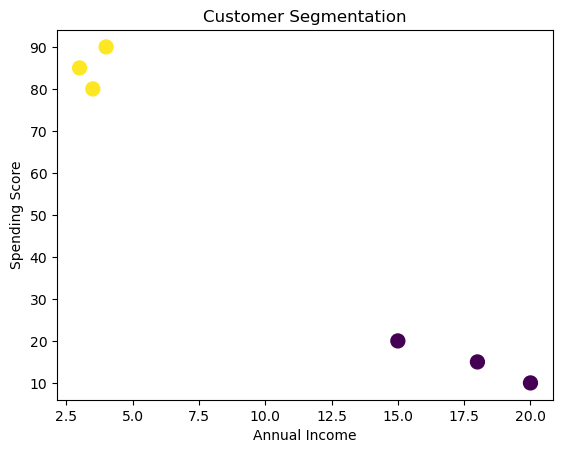

In [12]:
import matplotlib.pyplot as plt

plt.scatter(
    X["income"],
    X["spending_score"],
    c=df["cluster"],
    cmap="viridis",
    s=100
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Customer Segmentation")
plt.show()

#### K-Means 

In [15]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt

In [18]:
df= pd.read_csv("../../Datasets/income.csv")
df.head(3)

,Name,Age,Income($)
0,Rob,27,70000
1,Michael,29,90000
2,Mohan,29,61000


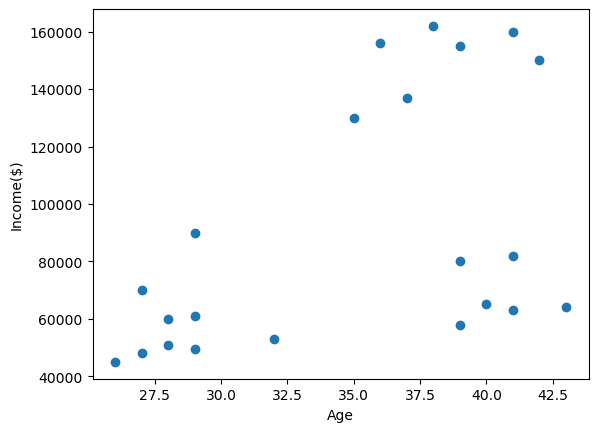

In [19]:
#ploting the data
plt.scatter(df.Age, df["Income($)"])
plt.xlabel("Age")
plt.ylabel("Income($)")
plt.show()

In [24]:
#training the model
from sklearn.cluster import KMeans

km= KMeans(n_clusters= 3, random_state= 42)
y_predicted= km.fit_predict(df[["Age", "Income($)"]])
y_predicted

C:\Users\Shaik\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
C:\Users\Shaik\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


array([1, 1, 2, 2, 0, 0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 2])

In [25]:
#creating new column in our dataframe
df["clusters"]= y_predicted
df.head()

,Name,Age,Income($),clusters
0,Rob,27,70000,1
1,Michael,29,90000,1
2,Mohan,29,61000,2
3,Ismail,28,60000,2
4,Kory,42,150000,0


In [26]:
#cluster points
km.cluster_centers_

array([[3.82857143e+01, 1.50000000e+05],
       [3.40000000e+01, 8.05000000e+04],
       [3.29090909e+01, 5.61363636e+04]])

In [27]:
df.Age

0     27
1     29
2     29
3     28
4     42
5     39
6     41
7     38
8     36
9     35
10    37
11    26
12    27
13    28
14    29
15    32
16    40
17    41
18    43
19    39
20    41
21    39
Name: Age, dtype: int64

In [28]:
df["Income($)"]

0      70000
1      90000
2      61000
3      60000
4     150000
5     155000
6     160000
7     162000
8     156000
9     130000
10    137000
11     45000
12     48000
13     51000
14     49500
15     53000
16     65000
17     63000
18     64000
19     80000
20     82000
21     58000
Name: Income($), dtype: int64

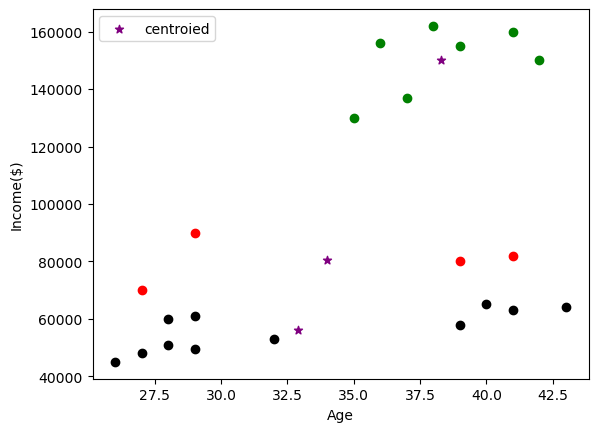

In [32]:
#### ploting all this into one scatter plot for better understanding 

df1= df[df.clusters== 0]
df2= df[df.clusters== 1]
df3= df[df.clusters== 2]
plt.scatter(df1.Age, df1["Income($)"], color= "green")
plt.scatter(df2.Age, df2["Income($)"], color= "red")
plt.scatter(df3.Age, df3["Income($)"], color= "black")
plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], color= "purple", marker= "*", label= "centroied")
plt.xlabel("Age")
plt.ylabel("Income($)")
plt.legend()
plt.show()